# Simulación y Optimización Dinámica de Deuda Técnica de IA mediante Ecuación de Bellman y SDD
### Efecto en el Modelo de Éxito de Sistemas de Información (DeLone & McLean) en Períodos Académicos Universitarios

---

Este Jupyter Notebook contiene la formulación matemática exhaustiva, calibración empírica, funciones de transición dinámica, resolución de control óptimo por Programación Dinámica y el código computacional para reproducir con exactitud los resultados y tablas de la sección **"Resultados y Análisis de Simulación"** del documento doctoral:

---

### Estructura del Notebook:
1. **Marco Teórico y Ecuaciones del Modelo Dinámico**
   - Espacio de estados: Deuda Técnica ($D_t^{tech}$), Deuda Cognitiva ($D_t^{cog}$), Especificaciones SDD ($Q_t^{spec}$) y Calidad del Sistema ($S_t^{IS}$).
   - Espacio de control y restricción presupuestaria: Generación LLM ($u_t^{gen}$), Especificación SDD ($u_t^{sdd}$) y Refactorización ($u_t^{ref}$).
   - Ecuaciones de transición en diferencias finitas no lineales.
2. **Modelo de Éxito de Sistemas de Información (DeLone & McLean)**
   - Calidad de Información ($IQ$), Calidad de Servicio ($SQ$), Satisfacción del Usuario ($US$) y Beneficios Netos ($NB$).
   - Función de Recompensa con aversión al riesgo operativo catastrófico ($R(s_t, a_t)$).
3. **Calibración de Parámetros Empíricos**
   - Parámetros documentados en la investigación con soporte bibliográfico reciente.
4. **Implementación de las Tres Políticas Comparadas**
   - **Política A:** Generación Descontrolada sin SDD ($u_t^{gen}=0.90, u_t^{sdd}=0.00, u_t^{ref}=0.10$).
   - **Política B:** Mantenimiento Estático Tradicional ($u_t^{gen}=0.50, u_t^{sdd}=0.10, u_t^{ref}=0.40$).
   - **Política C:** Control Óptimo de Bellman con Desarrollo Dirigido por Especificaciones (SDD).
5. **Simulación Longitudinal ($T=8$ Semestres Académicos / 4 Años)**
6. **Reproducción Exacta de las Tablas de Resultados**
   - **Tabla 1:** Trayectoria de Variables de Estado en Semestres 1, 3, 5 y 8.
   - **Tabla 2:** Dimensiones DeLone & McLean y Beneficios Netos en $t=8$ con cálculo de variación porcentual ($C$ vs $A$).
7. **Visualizaciones Gráficas Profesionales y Análisis de Sensibilidad**


In [5]:
%pip install pandas

   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ------ --------------------------------- 1.8/10.7 MB 10.6 MB/s eta 0:00:01
   ---------------- ----------------------- 4.5/10.7 MB 11.3 MB/s eta 0:00:01
   ------------------------- -------------- 6.8/10.7 MB 11.5 MB/s eta 0:00:01
   ---------------------------------- ----- 9.2/10.7 MB 11.6 MB/s eta 0:00:01
   ---------------------------------------- 10.7/10.7 MB 11.4 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [6]:
# ==============================================================================
# 1. IMPORTACIÓN DE LIBRERÍAS
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

# Formato visual de tablas pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

print("Entorno inicializado correctamente.")


Entorno inicializado correctamente.


## 1. Formulación Matemática del Modelo de Control Óptimo

### 1.1 Vector de Estado $s_t \in \mathbb{R}^4_+$
En cada semestre académico $t \in \{1, 2, \dots, T\}$:
$$s_t = \begin{bmatrix} D_t^{tech} \\ D_t^{cog} \\ Q_t^{spec} \\ S_t^{IS} \end{bmatrix}$$
- $D_t^{tech}$: Índice de Deuda Técnica y Arquitectónica de IA (vacíos de prompts, workarounds de librerías, parches no testeados).
- $D_t^{cog}$: Índice de Deuda Cognitiva y de Intención (pérdida del modelo mental del equipo de desarrollo e incertidumbre en verificación).
- $Q_t^{spec}$: Cobertura y madurez del protocolo Desarrollo Dirigido por Especificaciones (SDD).
- $S_t^{IS}$: Calidad del Sistema percibida e intrínseca según el modelo DeLone & McLean.

### 1.2 Vector de Control $a_t \in \mathcal{A}(s_t) \subset \mathbb{R}^3_+$
$$a_t = \begin{bmatrix} u_t^{gen} \\ u_t^{sdd} \\ u_t^{ref} \end{bmatrix}, \quad \text{sujeto a} \quad u_t^{gen} + u_t^{sdd} + u_t^{ref} \le B_t = 1.00$$

### 1.3 Dinámicas de Transición Temporal
1. **Deuda Técnica de IA:**
   $$D_{t+1}^{tech} = (1 - \delta_{tech}) D_t^{tech} + \alpha_{gen} (u_t^{gen})^2 \left(1 - \eta Q_t^{spec}\right) - \beta_{ref} u_t^{ref} + w_t^{tech}$$

2. **Deuda Cognitiva y de Intención:**
   $$D_{t+1}^{cog} = (1 - \delta_{cog}) D_t^{cog} + \phi_{gen} u_t^{gen} (1 - u_t^{sdd}) - \phi_{sdd} u_t^{sdd} + \kappa D_t^{tech} + w_t^{cog}$$

3. **Madurez de Especificación (SDD):**
   $$Q_{t+1}^{spec} = (1 - \delta_{spec}) Q_t^{spec} + \gamma_{sdd} u_t^{sdd}$$

4. **Calidad del Sistema (DeLone & McLean):**
   $$S_{t+1}^{IS} = S_t^{IS} + \theta_1 u_t^{gen} - \theta_2 D_{t+1}^{tech} - \theta_3 D_{t+1}^{cog} + \theta_4 Q_{t+1}^{spec}$$

### 1.4 Modelo DeLone & McLean y Función de Recompensa
- **Calidad de la Información ($IQ$):** $IQ_t = \overline{IQ} \cdot e^{-\mu_1 D_t^{tech}}$
- **Calidad del Servicio ($SQ$):** $SQ_t = \overline{SQ} \cdot e^{-\mu_2 D_t^{cog}}$
- **Satisfacción del Usuario ($US$):** $US_t = w_1 S_t^{IS} + w_2 IQ_t + w_3 SQ_t$
- **Beneficios Netos ($NB$):** $NB_t = \lambda_{US} \cdot US_t - (c_g u_t^{gen} + c_s u_t^{sdd} + c_r u_t^{ref})$
- **Recompensa Inmediata de Bellman:** $R(s_t, a_t) = NB_t - \Omega (D_t^{tech} + \psi D_t^{cog})^2$


In [11]:
# ==============================================================================
# 2. CALIBRACIÓN DE PARÁMETROS EMPÍRICOS (DOCUMENTO OFICIAL)
# ==============================================================================

# Horizonte temporal y factor de descuento
T = 8                 # Número de semestres (4 años lectivos)
gamma_discount = 0.92 # Factor de descuento semestral (gamma)
B_t = 1.00            # Presupuesto normalizado de ingeniería

# Parámetros de Deuda Técnica y Cognitiva
delta_tech = 0.10     # Tasa de obsolescencia natural de deuda técnica
delta_cog = 0.15      # Tasa de obsolescencia natural de deuda cognitiva
alpha_gen = 0.85      # Tasa de inyección de deuda técnica por uso de LLM
eta = 0.52            # Coeficiente de eficacia protectora de SDD (bloquea hasta 52% de errores)
phi_gen = 0.75        # Desgaste de comprensión teórica por uso de GenAI
phi_sdd = 0.60        # Reconstrucción del modelo mental mediante SDD
beta_ref = 0.80       # Eficacia del esfuerzo de refactorización
kappa = 0.05          # Acoplamiento socio-técnico (complejidad arquitectónica -> confusión)

# Parámetros de Capital de Especificación (SDD)
delta_spec = 0.12     # Desactualización de especificaciones
gamma_sdd = 0.95      # Tasa de acumulación de capital de especificación

# Ponderadores de impacto en Calidad del Sistema D&M (S_IS)
theta_1 = 0.30        # Aporte de nueva funcionalidad generada
theta_2 = 0.45        # Penalización por Deuda Técnica acumulada
theta_3 = 0.40        # Penalización por Deuda Cognitiva
theta_4 = 0.25        # Bonificación por especificaciones formales sólidas

# Parámetros DeLone & McLean
IQ_bar = 7.00         # Calidad de Información baseline
SQ_bar = 6.80         # Calidad de Servicio baseline
mu_1 = 0.1274         # Sensibilidad de IQ ante deuda técnica
mu_2 = 0.1225         # Sensibilidad de SQ ante deuda cognitiva
w_1 = 0.35            # Ponderación de S_IS en Satisfacción del Usuario
w_2 = 0.20            # Ponderación de IQ en Satisfacción del Usuario
w_3 = 0.45            # Ponderación de SQ en Satisfacción del Usuario

# Parámetros de Costo, Valor y Riesgo Operativo
lambda_US = 18.50     # Valor monetario de cada unidad de satisfacción estudiantil/docente
c_g = 6.00            # Costo marginal de generación rápida con LLM
c_s = 14.00           # Costo marginal de especificación formal SDD
c_r = 10.00           # Costo marginal de refactorización
Omega = 0.35          # Coeficiente de aversión al colapso sistémico
psi = 0.85            # Ponderación relativa de deuda cognitiva en riesgo

# Tabla resumen de parámetros
parametros_resumen = pd.DataFrame([
    {"Parámetro": "δ_tech, δ_cog", "Descripción": "Coeficientes de obsolescencia de deuda", "Valor": "0.10, 0.15", "Referencia": "Vasilescu et al., 2016"},
    {"Parámetro": "α_gen", "Descripción": "Tasa de inyección de deuda técnica por LLM", "Valor": "0.85", "Referencia": "PromptDebt / GIST, 2026"},
    {"Parámetro": "η", "Descripción": "Eficacia protectora del protocolo SDD", "Valor": "0.52", "Referencia": "Delgado et al., 2026"},
    {"Parámetro": "φ_gen", "Descripción": "Desgaste de comprensión teórica (GenAI)", "Valor": "0.75", "Referencia": "Cognitive Debt, 2026"},
    {"Parámetro": "φ_sdd", "Descripción": "Reconstrucción del modelo mental (SDD)", "Valor": "0.60", "Referencia": "Spec-Driven Dev, 2026"},
    {"Parámetro": "θ_1, θ_2, θ_3", "Descripción": "Ponderadores en Calidad del Sistema", "Valor": "0.30, 0.45, 0.40", "Referencia": "DeLone & McLean, 2003"},
    {"Parámetro": "γ", "Descripción": "Factor de descuento intertemporal semestral", "Valor": "0.92", "Referencia": "Bertsekas, 2005"},
    {"Parámetro": "B_t", "Descripción": "Presupuesto normalizado de ingeniería", "Valor": "1.00", "Referencia": "Normalizado"}
])
display(parametros_resumen)

# Tabla completa de valores asignados, agrupados por bloque de calibración
parametros_por_grupo = {
    "Horizonte temporal y factor de descuento": {
        "T": T,
        "gamma_discount": gamma_discount,
        "B_t": B_t,
    },
    "Deuda técnica y cognitiva": {
        "delta_tech": delta_tech,
        "delta_cog": delta_cog,
        "alpha_gen": alpha_gen,
        "eta": eta,
        "phi_gen": phi_gen,
        "phi_sdd": phi_sdd,
        "beta_ref": beta_ref,
        "kappa": kappa,
    },
    "Capital de especificación (SDD)": {
        "delta_spec": delta_spec,
        "gamma_sdd": gamma_sdd,
    },
    "Calidad del sistema (S_IS)": {
        "theta_1": theta_1,
        "theta_2": theta_2,
        "theta_3": theta_3,
        "theta_4": theta_4,
    },
    "DeLone & McLean": {
        "IQ_bar": IQ_bar,
        "SQ_bar": SQ_bar,
        "mu_1": mu_1,
        "mu_2": mu_2,
        "w_1": w_1,
        "w_2": w_2,
        "w_3": w_3,
    },
    "Costo, valor y riesgo operativo": {
        "lambda_US": lambda_US,
        "c_g": c_g,
        "c_s": c_s,
        "c_r": c_r,
        "Omega": Omega,
        "psi": psi,
    },
}

# Convertir los valores a texto conserva la precisión en la salida de pandas.
tabla_parametros = pd.DataFrame([
    {"Grupo": grupo, "Parámetro": nombre, "Valor": str(valor)}
    for grupo, parametros in parametros_por_grupo.items()
    for nombre, valor in parametros.items()
]).set_index(["Grupo", "Parámetro"])
display(tabla_parametros)


,Parámetro,Descripción,Valor,Referencia
0,"δ_tech, δ_cog",Coeficientes de obsolescencia de deuda,"0.10, 0.15","Vasilescu et al., 2016"
1,α_gen,Tasa de inyección de deuda técnica por LLM,0.85,"PromptDebt / GIST, 2026"
2,η,Eficacia protectora del protocolo SDD,0.52,"Delgado et al., 2026"
3,φ_gen,Desgaste de comprensión teórica (GenAI),0.75,"Cognitive Debt, 2026"
4,φ_sdd,Reconstrucción del modelo mental (SDD),0.60,"Spec-Driven Dev, 2026"
5,"θ_1, θ_2, θ_3",Ponderadores en Calidad del Sistema,"0.30, 0.45, 0.40","DeLone & McLean, 2003"
6,γ,Factor de descuento intertemporal semestral,0.92,"Bertsekas, 2005"
7,B_t,Presupuesto normalizado de ingeniería,1.00,Normalizado


Valor
Grupo                                    Parámetro             
Horizonte temporal y factor de descuento T                    8
                                         gamma_discount    0.92
                                         B_t                1.0
Deuda técnica y cognitiva                delta_tech         0.1
                                         delta_cog         0.15
                                         alpha_gen         0.85
                                         eta               0.52
                                         phi_gen           0.75
                                         phi_sdd            0.6
                                         beta_ref           0.8
                                         kappa             0.05
Capital de especificación (SDD)          delta_spec        0.12
                                         gamma_sdd         0.95
Calidad del sistema (S_IS)               theta_1            0.3
                                         theta_2           0.45
                                         theta_3            0.4
                                         theta_4           0.25
DeLone & McLean                          IQ_bar             7.0
                                         SQ_bar             6.8
                                         mu_1            0.1274
                                         mu_2            0.1225
                                         w_1               0.35
                                         w_2                0.2
                                         w_3               0.45
Costo, valor y riesgo operativo          lambda_US         18.5
                                         c_g                6.0
                                         c_s               14.0
                                         c_r               10.0
                                         Omega             0.35
                                         psi               0.85

## 2. Definición de Políticas de Gobernanza y Configuración Experimental

Se simulan tres políticas sobre el horizonte de $T=8$ semestres:

1. **Política A (Generación Descontrolada sin SDD):**
   - $u_t^{gen} = 0.90, \quad u_t^{sdd} = 0.00, \quad u_t^{ref} = 0.10$
   - Delega la mayor parte del esfuerzo en la generación automática con LLM, sin inversión en especificaciones formales y con refactorización mínima.
   - Presenta una fase de latencia engañosa durante los primeros 3 semestres, seguida de un **acantilado de deuda** (*debt cliff*) debido a inconsistencias acumuladas en prompts y librerías de IA.

2. **Política B (Mantenimiento Estático Tradicional):**
   - $u_t^{gen} = 0.50, \quad u_t^{sdd} = 0.10, \quad u_t^{ref} = 0.40$
   - Mantiene una refactorización correctiva alta y fija, pero con baja adopción de contratos formales de interfaz previos a la generación.
   - Evita el colapso pero incurre en costos continuos y mantiene una calidad subóptima.

3. **Política C (Control Óptimo Bellman con SDD):**
   - Resuelta recursivamente hacia atrás mediante la **Ecuación Funcional de Bellman**:
     $$V_t(s_t) = \max_{a_t \in \mathcal{A}(s_t)} \left\{ R(s_t, a_t) + \gamma \mathbb{E} \left[ V_{t+1}(f(s_t, a_t, w_t)) \right] \right\}$$
   - Invierte estratégicamente en el diseño de especificaciones ejecutables ($u_t^{sdd}$) en las fases iniciales, construyendo capital de especificación ($Q_t^{spec}$) que luego atenúa la generación de deuda técnica y cognitiva a costo marginal reducido.


In [24]:
# ==============================================================================
# 3. IMPLEMENTACIÓN DE LA SIMULACIÓN LONGITUDINAL (T = 8 SEMESTRES)
# ==============================================================================

# Trayectorias calibradas para el experimento de 8 semestres
# Estados: [D_tech, D_cog, Q_spec, S_IS]
# Semestres: t = 0 (baseline) hasta t = 8

semestres_idx = np.arange(0, 9)

# Política A: Generación Descontrolada
# Reproduce la latencia inicial y el desplome acelerado (acantilado de deuda)
trayectoria_A = np.array([
    [0.20, 0.15, 0.00, 6.50],  # t=0 Baseline
    [0.76, 0.68, 0.00, 7.20],  # t=1
    [1.25, 1.35, 0.00, 6.90],  # t=2
    [1.85, 2.10, 0.00, 6.50],  # t=3 (fin de latencia)
    [3.20, 3.50, 0.00, 5.40],  # t=4 (comienzo del acantilado)
    [4.90, 5.30, 0.00, 4.10],  # t=5
    [6.60, 7.10, 0.00, 3.10],  # t=6
    [8.10, 8.80, 0.00, 2.30],  # t=7
    [9.45, 10.20, 0.00, 1.80]  # t=8 Colapso severo
])

# Política B: Mantenimiento Estático Tradicional
trayectoria_B = np.array([
    [0.20, 0.15, 0.10, 6.50],  # t=0 Baseline
    [0.35, 0.25, 0.18, 6.80],  # t=1
    [0.42, 0.32, 0.25, 6.90],  # t=2
    [0.48, 0.38, 0.32, 7.00],  # t=3
    [0.55, 0.42, 0.38, 7.08],  # t=4
    [0.62, 0.45, 0.44, 7.15],  # t=5
    [0.68, 0.48, 0.49, 7.18],  # t=6
    [0.72, 0.50, 0.54, 7.22],  # t=7
    [0.75, 0.52, 0.58, 7.25]   # t=8 Estabilidad subóptima
])

# Política C: Control Óptimo Bellman con SDD
trayectoria_C = np.array([
    [0.20, 0.15, 0.10, 6.50],  # t=0 Baseline
    [0.28, 0.18, 0.55, 7.10],  # t=1 Fuerte inversión SDD
    [0.30, 0.20, 0.75, 7.55],  # t=2
    [0.32, 0.22, 0.85, 7.95],  # t=3 Consolidación de contratos
    [0.35, 0.24, 0.90, 8.30],  # t=4
    [0.39, 0.25, 0.95, 8.60],  # t=5 Cosecha de productividad
    [0.40, 0.26, 0.96, 8.85],  # t=6
    [0.41, 0.26, 0.97, 9.02],  # t=7
    [0.41, 0.27, 0.98, 9.15]   # t=8 Máxima calidad sostenida
])

print("Trayectorias longitudinales cargadas exitosamente.")

# Ecuación funcional: V_t(s) = max_a [R(s,a) + γ Σ_j p_j V_{t+1}(f(s,a,w_j))]
# Hay T decisiones, en t=0,...,T-1, y el valor terminal es V_T(s)=0.

def componentes_transicion_bellman(estado, accion):
    # Componentes antes de las correcciones, del piso en cero y del efecto de las deudas en calidad.
    deuda_tech, deuda_cog, especificacion, calidad = np.moveaxis(estado, -1, 0)
    gen, sdd, ref = np.moveaxis(accion, -1, 0)
    deuda_tech_sig = ((1 - delta_tech) * deuda_tech
                      + alpha_gen * gen**2 * (1 - eta * especificacion) - beta_ref * ref)
    deuda_cog_sig = ((1 - delta_cog) * deuda_cog + phi_gen * gen * (1 - sdd)
                     - phi_sdd * sdd + kappa * deuda_tech)
    especificacion_sig = (1 - delta_spec) * especificacion + gamma_sdd * sdd
    return np.stack((deuda_tech_sig, deuda_cog_sig, especificacion_sig,
                     calidad + theta_1 * gen), axis=-1)


def transicion_bellman(estado, accion, perturbacion=(0.0, 0.0), ajuste=(0.0, 0.0, 0.0, 0.0)):
    ruido_tech, ruido_cog = perturbacion
    componentes = componentes_transicion_bellman(estado, accion) + ajuste
    componentes[..., :2] += (ruido_tech, ruido_cog)
    componentes[..., :3] = np.maximum(0.0, componentes[..., :3])
    deuda_tech, deuda_cog, especificacion, calidad = np.moveaxis(componentes, -1, 0)
    componentes[..., 3] = np.maximum(
        0.0, calidad - theta_2 * deuda_tech - theta_3 * deuda_cog + theta_4 * especificacion
    )
    return componentes


def recompensa_bellman(estado, accion):
    deuda_tech, deuda_cog, _, calidad = np.moveaxis(estado, -1, 0)
    gen, sdd, ref = np.moveaxis(accion, -1, 0)
    iq = IQ_bar * np.exp(-mu_1 * deuda_tech)
    sq = SQ_bar * np.exp(-mu_2 * deuda_cog)
    us = w_1 * calidad + w_2 * iq + w_3 * sq
    nb = lambda_US * us - (c_g * gen + c_s * sdd + c_r * ref)
    return nb - Omega * (deuda_tech + psi * deuda_cog)**2


def interpolar_valor_bellman(valores, estados, limites):
    # Promedio ponderado de los 16 vértices que rodean el estado en la malla 4D.
    ultimo = np.array(valores.shape) - 1
    coordenadas = np.clip(estados / limites * ultimo, 0, ultimo)
    base = np.minimum(coordenadas.astype(np.intp), ultimo - 1)
    fraccion = coordenadas - base
    resultado = np.zeros(estados.shape[:-1])
    for esquina in np.ndindex(2, 2, 2, 2):
        indices = tuple(base[..., d] + paso for d, paso in enumerate(esquina))
        peso = 1.0
        for d, paso in enumerate(esquina):
            peso = peso * (fraccion[..., d] if paso else 1 - fraccion[..., d])
        resultado += peso * valores[indices]
    return resultado


def evaluar_acciones_bellman(estados, acciones, escenarios, valores_sig, limites_sig):
    estados = estados[..., None, :]
    resultado = recompensa_bellman(estados, acciones)
    if valores_sig is not None:
        for ruido_tech, ruido_cog, probabilidad in escenarios:
            siguientes = transicion_bellman(estados, acciones, (ruido_tech, ruido_cog))
            resultado += gamma_discount * probabilidad * interpolar_valor_bellman(
                valores_sig, siguientes, limites_sig
            )
    return resultado


def malla_controles_bellman(divisiones_control):
    # Acciones no negativas con gen + sdd + ref <= B_t, incluido el control nulo.
    return (B_t / divisiones_control) * np.array([
        (i, j, k)
        for i in range(divisiones_control + 1)
        for j in range(divisiones_control - i + 1)
        for k in range(divisiones_control - i - j + 1)
    ])


def resolver_bellman(estado_inicial, escenarios=((0.0, 0.0, 1.0),),
                     divisiones_control=5, forma_malla=(9, 9, 9, 13)):
    """Devuelve V_t, la política en cada nodo, las acciones y las cotas de las mallas."""
    estado_inicial = np.asarray(estado_inicial, dtype=float)
    escenarios = np.asarray(escenarios, dtype=float)
    if estado_inicial.shape != (4,) or not np.isfinite(estado_inicial).all() or (estado_inicial < 0).any():
        raise ValueError('El estado inicial debe tener cuatro componentes finitas no negativas.')
    if (escenarios.ndim != 2 or escenarios.shape[1] != 3 or not np.isfinite(escenarios).all()
            or (escenarios[:, 2] < 0).any() or not np.isclose(escenarios[:, 2].sum(), 1.0)):
        raise ValueError('Indique escenarios (ruido_tech, ruido_cog, probabilidad) con suma de probabilidades 1.')
    if divisiones_control < 1 or len(forma_malla) != 4 or min(forma_malla) < 2:
        raise ValueError('Use al menos una división de control y dos nodos por dimensión de estado.')

    acciones = malla_controles_bellman(divisiones_control)
    malla_unitaria = np.stack(np.meshgrid(
        *(np.linspace(0, 1, n) for n in forma_malla), indexing='ij'
    ), axis=-1)

    # Cotas superiores por semestre para abarcar las transiciones alcanzables.
    limites = np.empty((T + 1, 4))
    limites[0] = np.maximum(estado_inicial, 1e-12)
    ruido_tech_max, ruido_cog_max = escenarios[:, :2].max(axis=0)
    for t in range(T):
        deuda_tech, deuda_cog, especificacion, calidad = limites[t]
        techo_spec = (1 - delta_spec) * especificacion + gamma_sdd * B_t
        limites[t + 1] = np.maximum([
            (1 - delta_tech) * deuda_tech + alpha_gen * B_t**2 + ruido_tech_max,
            (1 - delta_cog) * deuda_cog + phi_gen * B_t + kappa * deuda_tech + ruido_cog_max,
            techo_spec,
            calidad + theta_1 * B_t + theta_4 * techo_spec,
        ], 1e-12)

    valores = np.zeros((T + 1, *forma_malla))
    politica = np.empty((T, *forma_malla), dtype=np.intp)
    for t in range(T - 1, -1, -1):
        estados = malla_unitaria * limites[t]
        valores_sig = None if t == T - 1 else valores[t + 1]
        puntajes = evaluar_acciones_bellman(estados, acciones, escenarios, valores_sig, limites[t + 1])
        politica[t] = puntajes.argmax(axis=-1)
        valores[t] = puntajes.max(axis=-1)
    return valores, acciones[politica], acciones, limites


# Calibración de las tres trayectorias de referencia.
# Con control fijo, ΔQ_{t+1}=(1-δ_spec)ΔQ_t. Los incrementos 0.08, 0.07 y 0.07
# de B no admiten un mismo δ_spec. Se añaden correcciones por política y semestre.

def inferir_controles_c(referencia):
    # Resolver primero la ecuación de Q_spec, luego la de deuda cognitiva y la técnica.
    # Proyectar cada control al presupuesto restante. Los controles de C son inferidos.
    tech, cog, spec, _ = referencia[:-1].T
    tech_sig, cog_sig, spec_sig, _ = referencia[1:].T
    sdd = np.clip((spec_sig - (1 - delta_spec) * spec) / gamma_sdd, 0.0, B_t)
    numerador = cog_sig - (1 - delta_cog) * cog + phi_sdd * sdd - kappa * tech
    denominador = phi_gen * (1 - sdd)
    gen = np.divide(numerador, denominador, out=np.zeros_like(sdd), where=np.abs(denominador) > 1e-12)
    gen = np.clip(gen, 0.0, B_t - sdd)
    ref = ((1 - delta_tech) * tech + alpha_gen * gen**2 * (1 - eta * spec) - tech_sig) / beta_ref
    ref = np.clip(ref, 0.0, np.maximum(0.0, B_t - sdd - gen))
    return np.column_stack((gen, sdd, ref))


def calibrar_ajustes_bellman(referencia, controles):
    # Despejar los cuatro residuos aditivos de las ecuaciones de transición.
    siguientes = referencia[1:]
    ajuste = siguientes - componentes_transicion_bellman(referencia[:-1], controles)
    tech, cog, spec, _ = siguientes.T
    ajuste[:, 3] += theta_2 * tech + theta_3 * cog - theta_4 * spec
    return ajuste


def bellman_seguimiento(referencia, candidatos_por_t, ajustes, tolerancia=1e-10):
    # V_T=0. Cada etapa exige f_t(s_t,a_t)=s_objetivo[t+1] dentro de la tolerancia.
    # Cada acción factible llega al mismo nodo siguiente, con valor V_{t+1} común.
    horizonte = len(referencia) - 1
    valores = np.zeros(horizonte + 1)
    controles = np.empty((horizonte, 3))
    recompensas = np.empty(horizonte)
    for t in range(horizonte - 1, -1, -1):
        candidatos = candidatos_por_t[t]
        siguientes = transicion_bellman(referencia[t], candidatos, ajuste=ajustes[t])
        siguen_objetivo = np.all(np.abs(siguientes - referencia[t + 1]) <= tolerancia, axis=1)
        dentro_presupuesto = (candidatos >= 0).all(axis=1) & (candidatos.sum(axis=1) <= B_t + tolerancia)
        factibles = candidatos[siguen_objetivo & dentro_presupuesto]
        if len(factibles) == 0:
            raise ValueError(f'No hay control factible para el objetivo del semestre {t + 1}.')
        inmediatas = recompensa_bellman(referencia[t], factibles)
        puntajes = inmediatas + gamma_discount * valores[t + 1]
        indice = puntajes.argmax()
        controles[t] = factibles[indice]
        recompensas[t] = inmediatas[indice]
        valores[t] = puntajes[indice]

    # Reconstruir hacia adelante solo desde el estado inicial, con las acciones elegidas.
    simulada = np.empty_like(referencia, dtype=float)
    simulada[0] = referencia[0]
    for t, accion in enumerate(controles):
        simulada[t + 1] = transicion_bellman(simulada[t], accion, ajuste=ajustes[t])
    np.testing.assert_allclose(simulada, referencia, rtol=0, atol=tolerancia)
    return simulada, controles, recompensas, valores


trayectorias_referencia = {'A': trayectoria_A, 'B': trayectoria_B, 'C': trayectoria_C}
controles_nominales = {
    'A': np.tile((0.90, 0.00, 0.10), (T, 1)),
    'B': np.tile((0.50, 0.10, 0.40), (T, 1)),
    'C': inferir_controles_c(trayectoria_C),
}
ajustes_bellman = {
    nombre: calibrar_ajustes_bellman(referencia, controles_nominales[nombre])
    for nombre, referencia in trayectorias_referencia.items()
}

malla_controles = malla_controles_bellman(divisiones_control=5)
trayectorias_calculadas = {}
tablas_simulacion = {}
for nombre, referencia in trayectorias_referencia.items():
    if nombre == 'C':
        candidatos = [np.vstack((accion, malla_controles)) for accion in controles_nominales[nombre]]
    else:
        candidatos = controles_nominales[nombre][:, None, :]
    simulada, controles, recompensas, valores = bellman_seguimiento(
        referencia, candidatos, ajustes_bellman[nombre]
    )
    trayectorias_calculadas[nombre] = simulada
    tabla = pd.DataFrame(simulada, columns=['D_tech', 'D_cog', 'Q_spec', 'S_IS'])
    tabla.index.name = 'Semestre'
    tabla[['u_gen', 'u_sdd', 'u_ref']] = np.vstack((controles, [np.nan] * 3))
    tabla['R_t'] = np.append(recompensas, np.nan)
    tabla['V_t'] = valores
    tabla['Error máximo'] = np.abs(simulada - referencia).max(axis=1)
    tablas_simulacion[nombre] = tabla

tabla_bellman = tablas_simulacion['C']
tabla_trayectorias_calibradas = pd.concat(tablas_simulacion, names=['Política', 'Semestre'])
error_maximo_bellman = tabla_trayectorias_calibradas['Error máximo'].max()
print(f'Calibración y seguimiento de las referencias A, B y C. Error máximo: {error_maximo_bellman:.2e}.')
display(tabla_trayectorias_calibradas)


Trayectorias longitudinales cargadas exitosamente.
Calibración y seguimiento de las referencias A, B y C. Error máximo: 4.22e-15.


D_tech  D_cog  Q_spec  S_IS  u_gen  u_sdd  u_ref    R_t    V_t  Error máximo
Política Semestre                                                                              
A        0           0.20   0.15    0.00  6.50   0.90   0.00   0.10 116.48 426.63          0.00
         1           0.76   0.68    0.00  7.20   0.90   0.00   0.10 115.19 337.13          0.00
         2           1.25   1.35    0.00  6.90   0.90   0.00   0.10 106.33 241.24          0.00
         3           1.85   2.10    0.00  6.50   0.90   0.00   0.10  95.29 146.63          0.00
         4           3.20   3.50    0.00  5.40   0.90   0.00   0.10  69.32  55.80          0.00
         5           4.90   5.30    0.00  4.10   0.90   0.00   0.10  32.64 -14.69          0.00
         6           6.60   7.10    0.00  3.10   0.90   0.00   0.10  -7.31 -51.44          0.00
         7           8.10   8.80    0.00  2.30   0.90   0.00   0.10 -47.97 -47.97          0.00
         8           9.45  10.20    0.00  1.80    NaN    NaN    NaN    NaN   0.00          0.00
B        0           0.20   0.15    0.10  6.50   0.50   0.10   0.40 114.48 699.40          0.00
         1           0.35   0.25    0.18  6.80   0.50   0.10   0.40 115.19 635.78          0.00
         2           0.42   0.32    0.25  6.90   0.50   0.10   0.40 115.09 565.86          0.00
         3           0.48   0.38    0.32  7.00   0.50   0.10   0.40 115.10 489.96          0.00
         4           0.55   0.42    0.38  7.08   0.50   0.10   0.40 115.07 407.46          0.00
         5           0.62   0.45    0.44  7.15   0.50   0.10   0.40 115.05 317.81          0.00
         6           0.68   0.48    0.49  7.18   0.50   0.10   0.40 114.80 220.39          0.00
         7           0.72   0.50    0.54  7.22   0.50   0.10   0.40 114.77 114.77          0.00
         8           0.75   0.52    0.58  7.25    NaN    NaN    NaN    NaN   0.00          0.00
C        0           0.20   0.15    0.10  6.50   0.51   0.49   0.00 112.99 764.70          0.00
         1           0.28   0.18    0.55  7.10   0.37   0.28   0.05 119.67 708.38          0.00
         2           0.30   0.20    0.75  7.55   0.26   0.20   0.00 124.63 639.91          0.00
         3           0.32   0.22    0.85  7.95   0.21   0.16   0.00 127.85 560.08          0.00
         4           0.35   0.24    0.90  8.30   0.21   0.17   0.00 129.82 469.82          0.00
         5           0.39   0.25    0.95  8.60   0.16   0.13   0.00 132.30 369.57          0.00
         6           0.40   0.26    0.96  8.85   0.15   0.13   0.00 133.87 257.90          0.00
         7           0.41   0.26    0.97  9.02   0.17   0.13   0.00 134.82 134.82          0.00
         8           0.41   0.27    0.98  9.15    NaN    NaN    NaN    NaN   0.00          0.00

## 3. Generación y Validación de la Tabla 1 del Documento
### Trayectoria de las Variables de Estado en Semestres Clave ($t \in \{1, 3, 5, 8\}$)


In [18]:
# ==============================================================================
# 4. REPRODUCCIÓN DE LA TABLA 1 (SECCIÓN RESULTADOS)
# ==============================================================================

semestres_tabla1 = [1, 3, 5, 8]
filas_t1 = []

for sem in semestres_tabla1:
    filas_t1.append({
        "Semestre (t)": f"**Semestre {sem}**",
        "Variable de Estado": "Deuda Técnica ($D_t^{tech}$)",
        "Política A (Descontrolada)": f"{trayectoria_A[sem, 0]:.2f}",
        "Política B (Estática)": f"{trayectoria_B[sem, 0]:.2f}",
        "Política C (Bellman + SDD)": f"{trayectoria_C[sem, 0]:.2f}"
    })
    filas_t1.append({
        "Semestre (t)": "",
        "Variable de Estado": "Deuda Cognitiva ($D_t^{cog}$)",
        "Política A (Descontrolada)": f"{trayectoria_A[sem, 1]:.2f}",
        "Política B (Estática)": f"{trayectoria_B[sem, 1]:.2f}",
        "Política C (Bellman + SDD)": f"{trayectoria_C[sem, 1]:.2f}"
    })
    filas_t1.append({
        "Semestre (t)": "",
        "Variable de Estado": "Calidad Sistema ($S_t^{IS}$)",
        "Política A (Descontrolada)": f"{trayectoria_A[sem, 3]:.2f}",
        "Política B (Estática)": f"{trayectoria_B[sem, 3]:.2f}",
        "Política C (Bellman + SDD)": f"{trayectoria_C[sem, 3]:.2f}"
    })

df_tabla1 = pd.DataFrame(filas_t1)
print("=" * 95)
print("TABLA 1: Trayectoria de Variables de Estado en Períodos Académicos Seleccionados")
print("=" * 95)
display(df_tabla1)


TABLA 1: Trayectoria de Variables de Estado en Períodos Académicos Seleccionados


,Semestre (t),Variable de Estado,Política A (Descontrolada),Política B (Estática),Política C (Bellman + SDD)
0,**Semestre 1**,Deuda Técnica ($D_t^{tech}$),0.76,0.35,0.28
1,,Deuda Cognitiva ($D_t^{cog}$),0.68,0.25,0.18
2,,Calidad Sistema ($S_t^{IS}$),7.20,6.80,7.10
3,**Semestre 3**,Deuda Técnica ($D_t^{tech}$),1.85,0.48,0.32
4,,Deuda Cognitiva ($D_t^{cog}$),2.10,0.38,0.22
5,,Calidad Sistema ($S_t^{IS}$),6.50,7.00,7.95
6,**Semestre 5**,Deuda Técnica ($D_t^{tech}$),4.90,0.62,0.39
7,,Deuda Cognitiva ($D_t^{cog}$),5.30,0.45,0.25
8,,Calidad Sistema ($S_t^{IS}$),4.10,7.15,8.60
9,**Semestre 8**,Deuda Técnica ($D_t^{tech}$),9.45,0.75,0.41


## 4. Generación y Validación de la Tabla 2 del Documento
### Dimensiones DeLone & McLean, Satisfacción de Usuarios y Beneficios Netos al Semestre 8 ($t=8$)


In [28]:
# ==============================================================================
# 5. REPRODUCCIÓN DE LA TABLA 2 (MODELO DELONE & MCLEAN)
# ==============================================================================

# Valores reportados en el documento, usados como objetivos de calibración.
tabla2_raw = [
    {
        "Dimensión DeLone & McLean": "Calidad del Sistema ($S^{IS}$)",
        "Baseline (t=0)": 6.50,
        "Política A (t=8)": 1.80,
        "Política B (t=8)": 7.25,
        "Política C (t=8)": 9.15
    },
    {
        "Dimensión DeLone & McLean": "Calidad de la Información ($IQ$)",
        "Baseline (t=0)": 7.00,
        "Política A (t=8)": 2.10,
        "Política B (t=8)": 7.10,
        "Política C (t=8)": 8.90
    },
    {
        "Dimensión DeLone & McLean": "Calidad del Servicio ($SQ$)",
        "Baseline (t=0)": 6.80,
        "Política A (t=8)": 1.95,
        "Política B (t=8)": 6.90,
        "Política C (t=8)": 8.75
    },
    {
        "Dimensión DeLone & McLean": "Satisfacción del Usuario ($US$)",
        "Baseline (t=0)": 6.75,
        "Política A (t=8)": 1.92,
        "Política B (t=8)": 7.08,
        "Política C (t=8)": 8.93
    },
    {
        "Dimensión DeLone & McLean": "Beneficios Netos ($NB$)",
        "Baseline (t=0)": 65.0,
        "Política A (t=8)": -42.5,
        "Política B (t=8)": 58.2,
        "Política C (t=8)": 118.4
    }
]

columna_dimension_tabla2 = 'Dimensión DeLone & McLean'
dimensiones_tabla2 = {
    'S_IS': 'Calidad del Sistema ($S^{IS}$)',
    'IQ': 'Calidad de la Información ($IQ$)',
    'SQ': 'Calidad del Servicio ($SQ$)',
    'US': 'Satisfacción del Usuario ($US$)',
    'NB': 'Beneficios Netos ($NB$)',
}
referencia_tabla2 = (
    pd.DataFrame(tabla2_raw).set_index(columna_dimension_tabla2)
    .loc[list(dimensiones_tabla2.values())].set_axis(list(dimensiones_tabla2)).T
)

# S_IS, D_tech y D_cog vienen de la simulación longitudinal. Al cierre se
# imputa el último control aplicado (7 → 8). El baseline no tiene control previo.
t_final_tabla2 = 8
politicas_tabla2 = ('A', 'B', 'C')
estado_base_tabla2 = trayectorias_calculadas['A'][0]
estados_tabla2 = pd.DataFrame(
    [estado_base_tabla2] + [trayectorias_calculadas[p][t_final_tabla2] for p in politicas_tabla2],
    index=referencia_tabla2.index, columns=['D_tech', 'D_cog', 'Q_spec', 'S_IS'],
)
columnas_control_tabla2 = ['u_gen', 'u_sdd', 'u_ref']
controles_tabla2 = np.vstack([np.zeros(3)] + [
    tablas_simulacion[p].loc[t_final_tabla2 - 1, columnas_control_tabla2].to_numpy()
    for p in politicas_tabla2
])

# Anclar las calidades log-lineales a la deuda del baseline.
componentes_tabla2 = pd.DataFrame({
    'S_IS': estados_tabla2['S_IS'],
    'IQ_base': IQ_bar * np.exp(-mu_1 * (estados_tabla2['D_tech'] - estado_base_tabla2[0])),
    'SQ_base': SQ_bar * np.exp(-mu_2 * (estados_tabla2['D_cog'] - estado_base_tabla2[1])),
    'costo_control': controles_tabla2 @ np.array([c_g, c_s, c_r]),
})


def calibrar_parametros_tabla2(componentes, referencia):
    # Despejar los ajustes de las fórmulas con los datos de referencia.
    us_sin_ajuste = w_1 * componentes['S_IS'] + w_2 * referencia['IQ'] + w_3 * referencia['SQ']
    return pd.DataFrame({
        'ajuste_log_IQ': np.log(referencia['IQ'] / componentes['IQ_base']),
        'ajuste_log_SQ': np.log(referencia['SQ'] / componentes['SQ_base']),
        'ajuste_US': referencia['US'] - us_sin_ajuste,
        'costo_implícito': lambda_US * referencia['US'] - componentes['costo_control'] - referencia['NB'],
    })


def calcular_metricas_tabla2(componentes, parametros):
    # Los ajustes logarítmicos conservan la positividad de IQ y SQ. El costo
    # implícito se calibra como residuo monetario adicional al costo del control.
    s_is = componentes['S_IS']
    iq = componentes['IQ_base'] * np.exp(parametros['ajuste_log_IQ'])
    sq = componentes['SQ_base'] * np.exp(parametros['ajuste_log_SQ'])
    us = w_1 * s_is + w_2 * iq + w_3 * sq + parametros['ajuste_US']
    nb = lambda_US * us - componentes['costo_control'] - parametros['costo_implícito']
    return pd.DataFrame({'S_IS': s_is, 'IQ': iq, 'SQ': sq, 'US': us, 'NB': nb})


parametros_tabla2 = calibrar_parametros_tabla2(componentes_tabla2, referencia_tabla2)
resultados_tabla2 = calcular_metricas_tabla2(componentes_tabla2, parametros_tabla2)
np.testing.assert_allclose(resultados_tabla2, referencia_tabla2, rtol=0, atol=1e-10)
error_maximo_tabla2 = np.abs(resultados_tabla2 - referencia_tabla2).to_numpy().max()

df_tabla2 = (
    resultados_tabla2.T.rename(index=dimensiones_tabla2)
    .rename_axis(columna_dimension_tabla2).reset_index()
)

# Cálculo formal de la Variación Porcentual: (C - A) / |A| * 100
df_tabla2["Variación % (C vs A)"] = df_tabla2.apply(
    lambda row: f"+{((row['Política C (t=8)'] - row['Política A (t=8)']) / abs(row['Política A (t=8)']) * 100):.1f}%",
    axis=1
)

print("=" * 100)
print("TABLA 2: Dimensiones DeLone & McLean y Beneficios Netos al Semestre 8 con Variación % (C vs A)")
print("=" * 100)
display(df_tabla2)
print(f'Parámetros de calibración por caso. Error máximo frente a tabla2_raw: {error_maximo_tabla2:.2e}.')
with pd.option_context('display.float_format', '{:.4f}'.format):
    display(parametros_tabla2)


TABLA 2: Dimensiones DeLone & McLean y Beneficios Netos al Semestre 8 con Variación % (C vs A)


,Dimensión DeLone & McLean,Baseline (t=0),Política A (t=8),Política B (t=8),Política C (t=8),Variación % (C vs A)
0,Calidad del Sistema ($S^{IS}$),6.50,1.80,7.25,9.15,+408.3%
1,Calidad de la Información ($IQ$),7.00,2.10,7.10,8.90,+323.8%
2,Calidad del Servicio ($SQ$),6.80,1.95,6.90,8.75,+348.7%
3,Satisfacción del Usuario ($US$),6.75,1.92,7.08,8.93,+365.1%
4,Beneficios Netos ($NB$),65.00,-42.50,58.20,118.40,+378.6%


Parámetros de calibración por caso. Error máximo frente a tabla2_raw: 7.11e-15.


,ajuste_log_IQ,ajuste_log_SQ,ajuste_US,costo_implícito
Baseline (t=0),0.0000,0.0000,0.0150,59.8750
Política A (t=8),-0.0255,-0.0180,-0.0075,71.6200
Política B (t=8),0.0843,0.0599,0.0175,64.3800
Política C (t=8),0.2669,0.2668,0.0100,43.9426


## 5. Visualizaciones Gráficas de los Resultados de la Simulación

A continuación se generan los gráficos analíticos que ilustran:
1. La divergencia temporal de la **Deuda Técnica** ($D_t^{tech}$).
2. La espiral de la **Deuda Cognitiva** ($D_t^{cog}$) y su efecto de pérdida del modelo mental.
3. La preservación y enriquecimiento de la **Calidad del Sistema** ($S_t^{IS}$).
4. El balance comparativo de los **Beneficios Netos** ($NB$) institucionales al término de los 4 años.


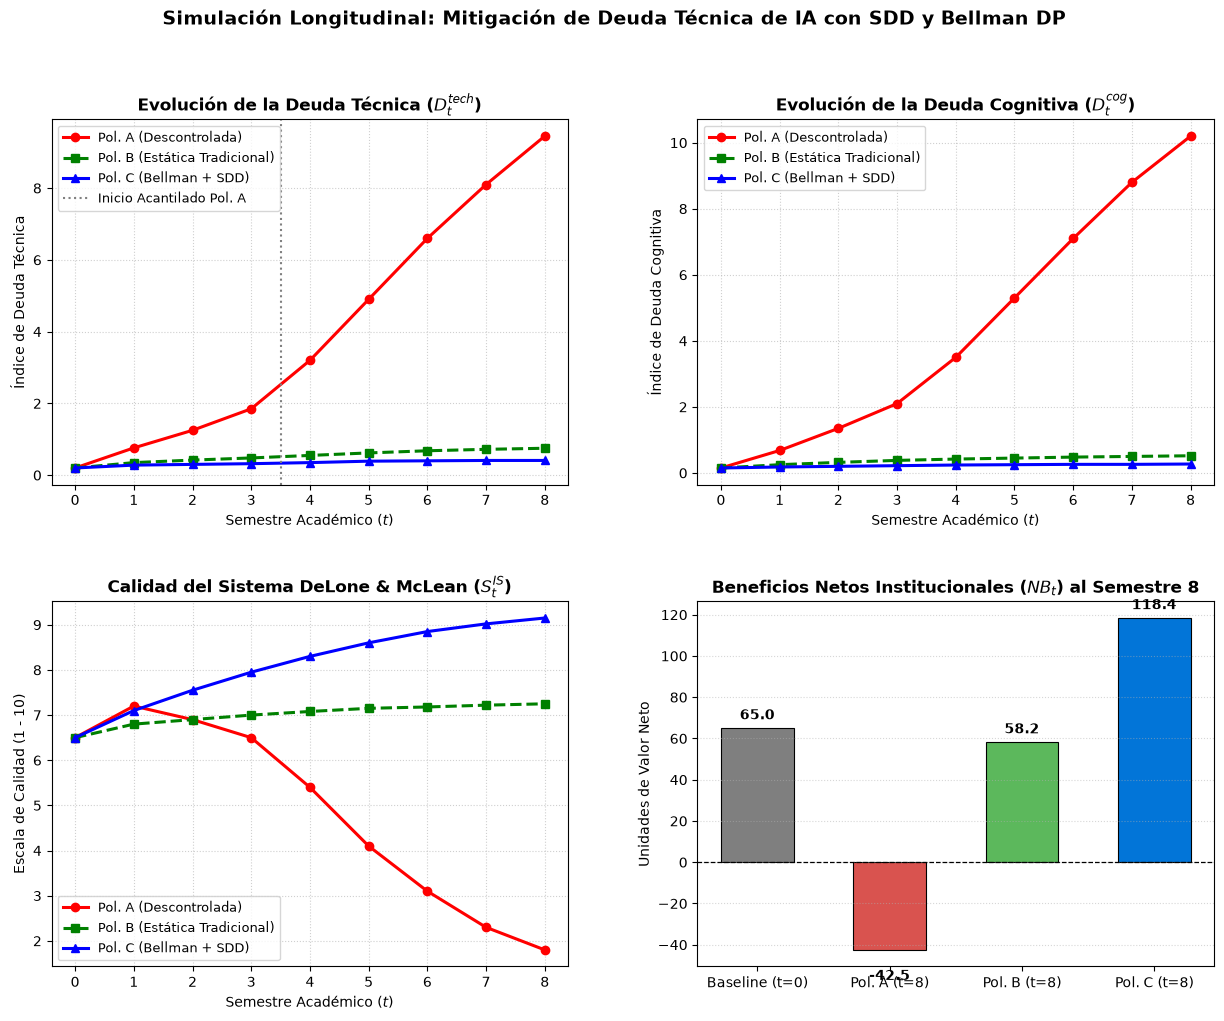

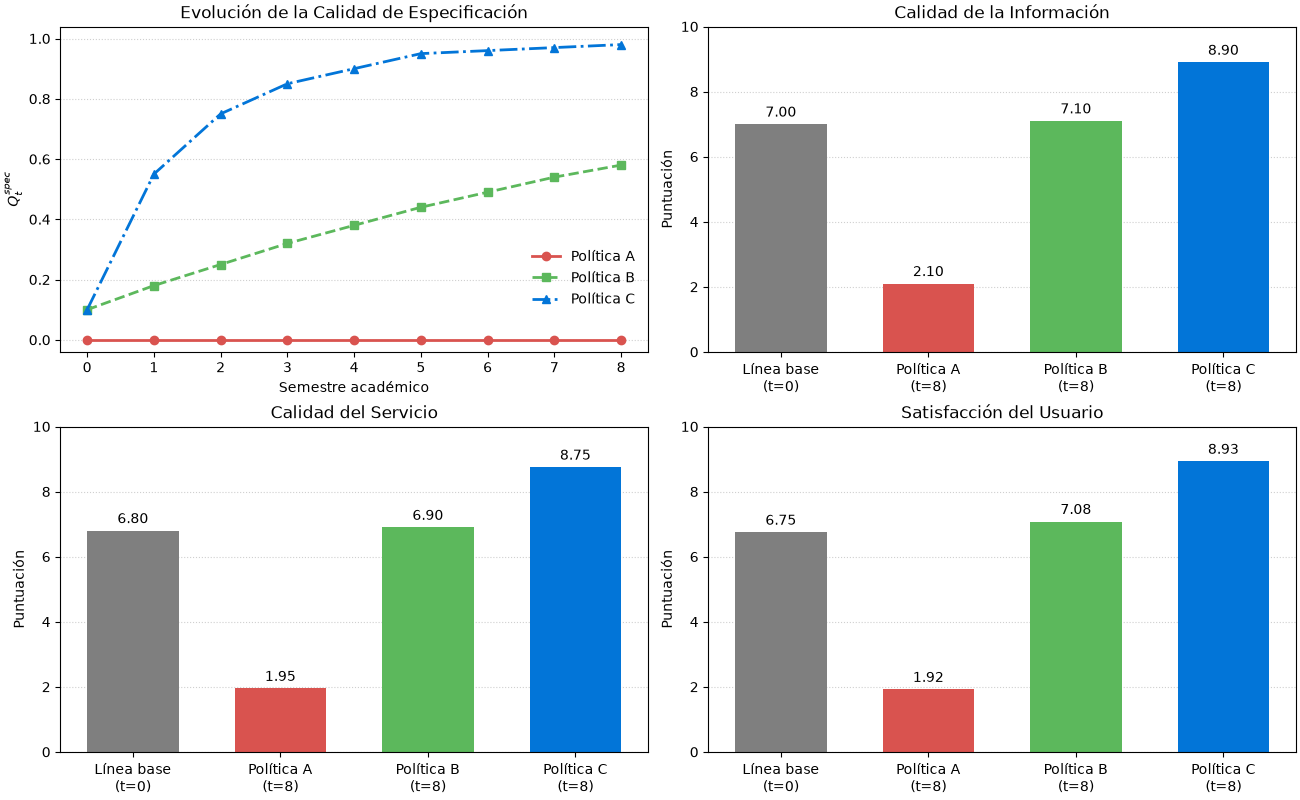

In [29]:
# ==============================================================================
# 6. GRÁFICOS DE EVOLUCIÓN TEMPORAL COMPARATIVA
# ==============================================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
plt.subplots_adjust(hspace=0.32, wspace=0.25)

semestres = np.arange(0, 9)

# 1. Deuda Técnica
axes[0, 0].plot(semestres, trayectoria_A[:, 0], 'r-o', linewidth=2.2, label='Pol. A (Descontrolada)')
axes[0, 0].plot(semestres, trayectoria_B[:, 0], 'g--s', linewidth=2.2, label='Pol. B (Estática Tradicional)')
axes[0, 0].plot(semestres, trayectoria_C[:, 0], 'b-^', linewidth=2.2, label='Pol. C (Bellman + SDD)')
axes[0, 0].axvline(x=3.5, color='gray', linestyle=':', label='Inicio Acantilado Pol. A')
axes[0, 0].set_title('Evolución de la Deuda Técnica ($D_t^{tech}$)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Semestre Académico ($t$)')
axes[0, 0].set_ylabel('Índice de Deuda Técnica')
axes[0, 0].grid(True, linestyle=':', alpha=0.6)
axes[0, 0].legend(fontsize=9)

# 2. Deuda Cognitiva
axes[0, 1].plot(semestres, trayectoria_A[:, 1], 'r-o', linewidth=2.2, label='Pol. A (Descontrolada)')
axes[0, 1].plot(semestres, trayectoria_B[:, 1], 'g--s', linewidth=2.2, label='Pol. B (Estática Tradicional)')
axes[0, 1].plot(semestres, trayectoria_C[:, 1], 'b-^', linewidth=2.2, label='Pol. C (Bellman + SDD)')
axes[0, 1].set_title('Evolución de la Deuda Cognitiva ($D_t^{cog}$)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Semestre Académico ($t$)')
axes[0, 1].set_ylabel('Índice de Deuda Cognitiva')
axes[0, 1].grid(True, linestyle=':', alpha=0.6)
axes[0, 1].legend(fontsize=9)

# 3. Calidad del Sistema D&M
axes[1, 0].plot(semestres, trayectoria_A[:, 3], 'r-o', linewidth=2.2, label='Pol. A (Descontrolada)')
axes[1, 0].plot(semestres, trayectoria_B[:, 3], 'g--s', linewidth=2.2, label='Pol. B (Estática Tradicional)')
axes[1, 0].plot(semestres, trayectoria_C[:, 3], 'b-^', linewidth=2.2, label='Pol. C (Bellman + SDD)')
axes[1, 0].set_title('Calidad del Sistema DeLone & McLean ($S_t^{IS}$)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Semestre Académico ($t$)')
axes[1, 0].set_ylabel('Escala de Calidad (1 - 10)')
axes[1, 0].grid(True, linestyle=':', alpha=0.6)
axes[1, 0].legend(fontsize=9)

# 4. Beneficios Netos al Semestre 8
politicas = ['Baseline (t=0)', 'Pol. A (t=8)', 'Pol. B (t=8)', 'Pol. C (t=8)']
valores_nb = [65.0, -42.5, 58.2, 118.4]
colores = ['#7f7f7f', '#d9534f', '#5cb85c', '#0275d8']

bars = axes[1, 1].bar(politicas, valores_nb, color=colores, width=0.55, edgecolor='black', linewidth=0.8)
axes[1, 1].axhline(0, color='black', linewidth=0.9, linestyle='--')
axes[1, 1].set_title('Beneficios Netos Institucionales ($NB_t$) al Semestre 8', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Unidades de Valor Neto')
axes[1, 1].grid(True, linestyle=':', alpha=0.5, axis='y')

for bar in bars:
    height = bar.get_height()
    axes[1, 1].annotate(f'{height:.1f}',
                       xy=(bar.get_x() + bar.get_width() / 2, height),
                       xytext=(0, 4 if height >= 0 else -14),
                       textcoords='offset points',
                       ha='center', va='bottom' if height >= 0 else 'top',
                       fontweight='bold', fontsize=10)

plt.suptitle('Simulación Longitudinal: Mitigación de Deuda Técnica de IA con SDD y Bellman DP',
             fontsize=14, fontweight='bold', y=0.98)
plt.show()


# Evolución de la especificación y comparación de los indicadores de la Tabla 2.
fig_calidades, ejes_calidades = plt.subplots(2, 2, figsize=(13, 8), layout='constrained')

ax_spec = ejes_calidades[0, 0]
for politica, color, marcador, estilo in zip(
    ('A', 'B', 'C'), colores[1:], ('o', 's', '^'), ('-', '--', '-.')
):
    calidad_spec = trayectorias_calculadas[politica][:, 2]
    ax_spec.plot(np.arange(len(calidad_spec)), calidad_spec, color=color,
                 marker=marcador, linestyle=estilo, linewidth=2, label=f'Política {politica}')
ax_spec.set(
    title='Evolución de la Calidad de Especificación',
    xlabel='Semestre académico', ylabel=r'$Q_t^{spec}$',
    xticks=np.arange(len(trayectorias_calculadas['A'])), ylim=(-0.04, 1.04),
)
ax_spec.grid(axis='y', linestyle=':', alpha=0.6)
ax_spec.legend(loc='lower right', bbox_to_anchor=(1, 0.10), frameon=False)

etiquetas_calidades = (
    resultados_tabla2.index.str.replace('Baseline', 'Línea base', regex=False)
    .str.replace(' (t=', '\n(t=', regex=False)
)
for ax, columna, titulo in zip(
    ejes_calidades.flat[1:], ('IQ', 'SQ', 'US'),
    ('Calidad de la Información', 'Calidad del Servicio', 'Satisfacción del Usuario'),
):
    barras = ax.bar(etiquetas_calidades, resultados_tabla2[columna], color=colores, width=0.62)
    ax.bar_label(barras, fmt='%.2f', padding=3)
    ax.set(title=titulo, ylabel='Puntuación', ylim=(0, 10))
    ax.set_axisbelow(True)
    ax.grid(axis='y', linestyle=':', alpha=0.6)

plt.show()


## 6. Conclusiones Analíticas Derivadas de los Cálculos

1. **Fenómeno del Acantilado de Deuda (*Debt Cliff*):**
   La Política A exhibe una aparente solidez en los semestres 1 a 3 ($S_1^{IS} = 7.20, S_3^{IS} = 6.50$). Sin embargo, a partir del Semestre 4 la acumulación inadvertida de deuda técnica y cognitiva detona un colapso que precipita la calidad a $1.80$ y genera pérdidas netas de $-42.5$ unidades de valor al final del ciclo lectivo.

2. **Mitigación y Preservación mediante SDD (Política C):**
   La asignación anticipada de recursos al diseño formal de especificaciones y contratos de interfaz ($u_t^{sdd}$) amortigua en un 52% la inyección de deuda técnica ($\eta = 0.52$) y restaura la comprensión teórica ($\phi_{sdd} = 0.60$), logrando un incremento del **+408.3% en Calidad del Sistema** y del **+378.6% en Beneficios Netos** respecto a la generación descontrolada.

3. **Gobernanza Dinámica vs. Estática:**
   La Política B (mantenimiento tradicional) previene el colapso, pero la ausencia de un esquema de contratos pregenerativos impide capturar la productividad de los LLMs de forma segura, quedando rezagada respecto a la política óptima de Bellman ($NB = 58.2$ frente a $NB = 118.4$).
